# Univariate analysis

Objective: predict whether a patient has heart disease.

| Column | Meaning |
| --- | --- |
| `age` | Age of the patient, years |
| `sex` | M / F |
| `chestpaintype` | TA typical angina, ATA atypical angina, NAP non-anginal pain, ASY asymptomatic |
| `restingbp` | Resting blood pressure, mm Hg |
| `cholesterol` | Serum cholesterol, mm/dl |
| `fastingbs` | 1 if fasting blood sugar > 120 mg/dl, else 0 |
| `restingecg` | Normal, ST wave abnormality, LVH left ventricular hypertrophy |
| `maxhr` | Maximum heart rate achieved, 60-202 |
| `exerciseangina` | Y / N, exercise-induced angina |
| `oldpeak` | ST depression |
| `st_slope` | Up, Flat or Down slope of the peak exercise ST segment |
| `heartdisease` | Target: 1 heart disease, 0 normal |

The clinical background for each of these is in `dictionary.md`.

In [1]:
import matplotlib.pyplot as plt
import seaborn as sns

import helpers
from helpers import CAT_COLS, NUM_COLS

helpers.setup()

In [2]:
data = helpers.load_data()
data.head()

,age,sex,chestpaintype,restingbp,cholesterol,fastingbs,restingecg,maxhr,exerciseangina,oldpeak,st_slope,heartdisease
0,40,M,ATA,140,289,0,Normal,172,N,0.0,Up,0
1,49,F,NAP,160,180,0,Normal,156,N,1.0,Flat,1
2,37,M,ATA,130,283,0,ST,98,N,0.0,Up,0
3,48,F,ASY,138,214,0,Normal,108,Y,1.5,Flat,1
4,54,M,NAP,150,195,0,Normal,122,N,0.0,Up,0


In [3]:
helpers.overview(data)

Shape: 918 rows, 12 columns
Duplicated rows: 0
----------------------------------------------------------------------------------------------------
Head:
   age sex chestpaintype  restingbp  cholesterol  fastingbs restingecg  maxhr exerciseangina  oldpeak st_slope  heartdisease
0   40   M           ATA        140          289          0     Normal    172              N      0.0       Up             0
1   49   F           NAP        160          180          0     Normal    156              N      1.0     Flat             1
2   37   M           ATA        130          283          0         ST     98              N      0.0       Up             0
3   48   F           ASY        138          214          0     Normal    108              Y      1.5     Flat             1
4   54   M           NAP        150          195          0     Normal    122              N      0.0       Up             0

Tail:
     age sex chestpaintype  restingbp  cholesterol  fastingbs restingecg  maxhr exercisea

Female records are far fewer than male ones, a ratio of about 4.8 : 1, so there is a mild class imbalance.
Several of the other categories are also much smaller than the dominant class, which gives the data a long tail.

## Numerical variables

In [4]:
data[NUM_COLS].describe().T

,count,mean,std,min,25%,50%,75%,max
age,918.0,53.510893,9.432617,28.0,47.00,54.0,60.0,77.0
restingbp,918.0,132.396514,18.514154,0.0,120.00,130.0,140.0,200.0
cholesterol,918.0,198.799564,109.384145,0.0,173.25,223.0,267.0,603.0
maxhr,918.0,136.809368,25.460334,60.0,120.00,138.0,156.0,202.0
oldpeak,918.0,0.887364,1.066570,-2.6,0.00,0.6,1.5,6.2


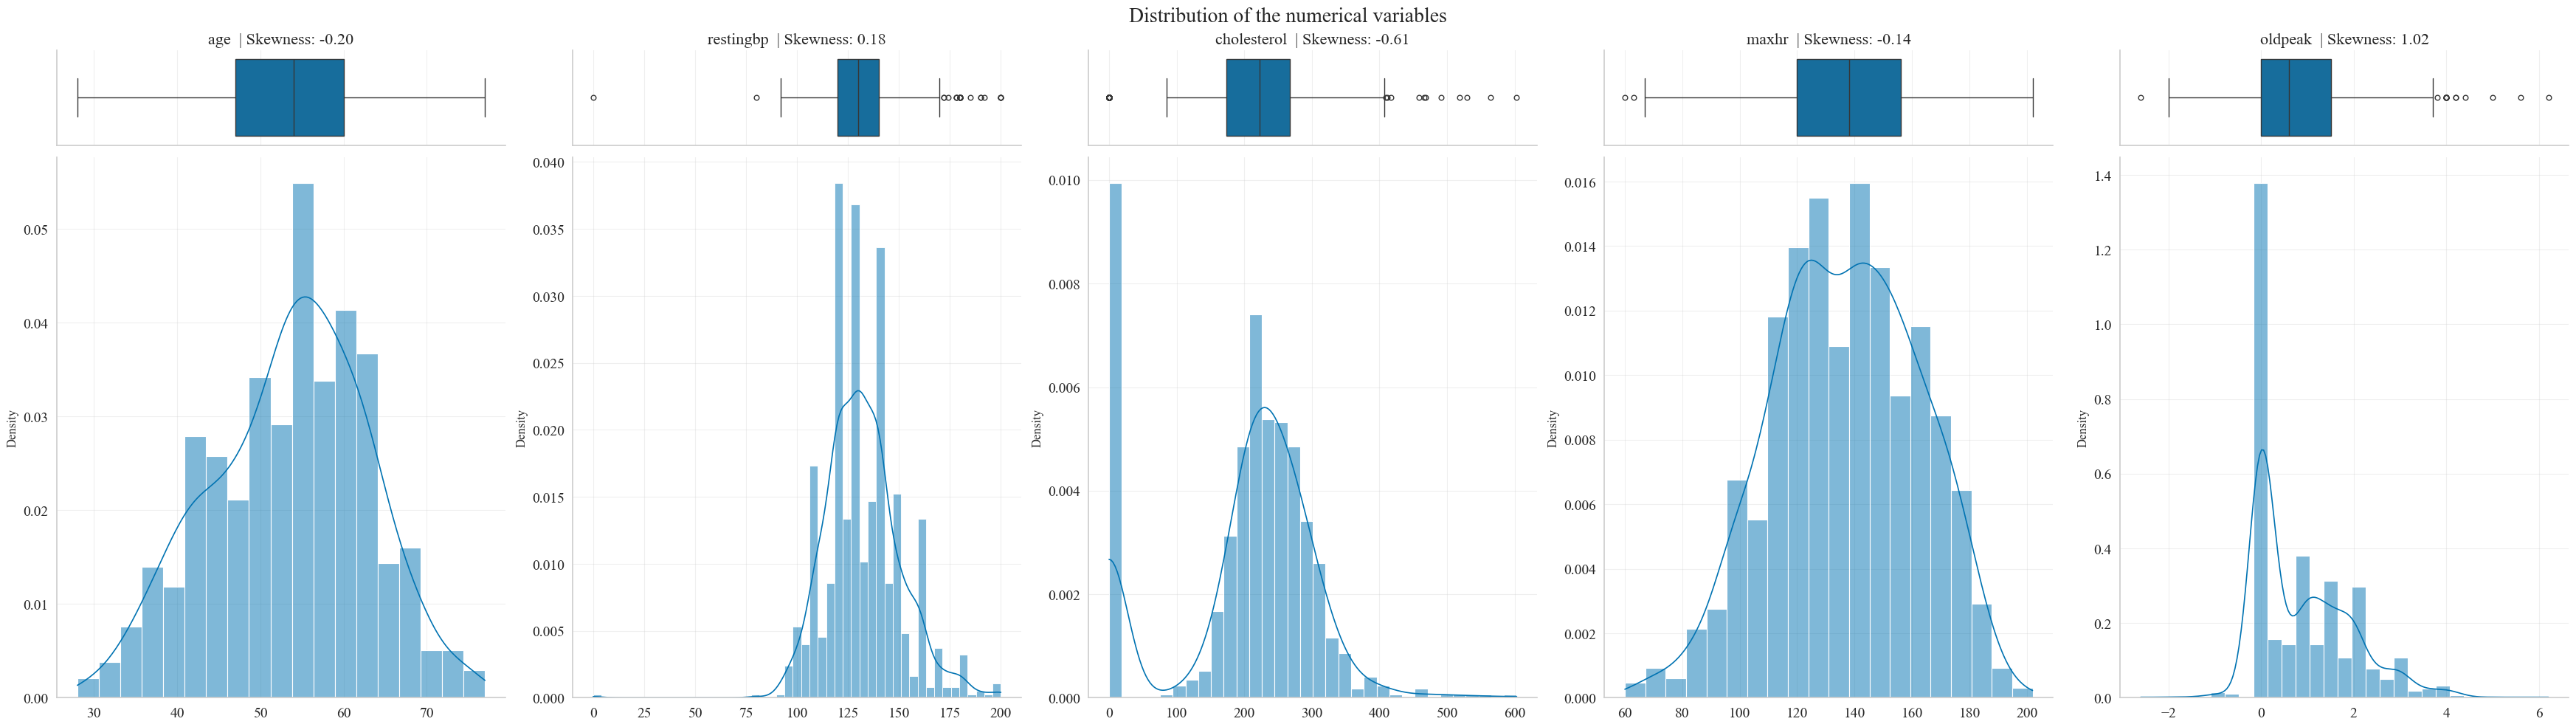

In [5]:
fig, axes = plt.subplots(2, len(NUM_COLS), figsize=(7 * len(NUM_COLS), 10),
                         sharex='col', gridspec_kw={'height_ratios': [0.15, 0.85]})
fig.suptitle('Distribution of the numerical variables', size=20)

for ax_box, ax_hist, col in zip(axes[0], axes[1], NUM_COLS):
    sns.boxplot(data=data, x=col, ax=ax_box)
    sns.histplot(data=data, x=col, ax=ax_hist, stat='density', kde=True)

    ax_box.set_title(f'{col}  | Skewness: {data[col].skew():.2f}', size=16)
    ax_box.set_xlabel('')
    ax_hist.set_xlabel('')
    ax_box.tick_params(axis='both', labelsize=14)
    ax_hist.tick_params(axis='both', labelsize=14)

plt.tight_layout()
plt.show()

In [6]:
for col in helpers.ZERO_AS_MISSING:
    zeros = (data[col] == 0).sum()
    print(f'{col}: {zeros} zeros ({zeros / len(data) * 100:.2f}%)')

cholesterol: 172 zeros (18.74%)
restingbp: 1 zeros (0.11%)


Cholesterol = 0 accounts for 18.74% of the dataset.

It's impossible for a person to have 0 cholesterol => this should be missingness

Restingbp = 0 => also a missingness => should be filled up

Restingbp lower than normal condition? I don't know what to do yet

## Categorical variables

In [7]:
data[CAT_COLS].describe(include='object').T

,count,unique,top,freq
sex,918,2,M,725
chestpaintype,918,4,ASY,496
restingecg,918,3,Normal,552
exerciseangina,918,2,N,547
st_slope,918,3,Flat,460


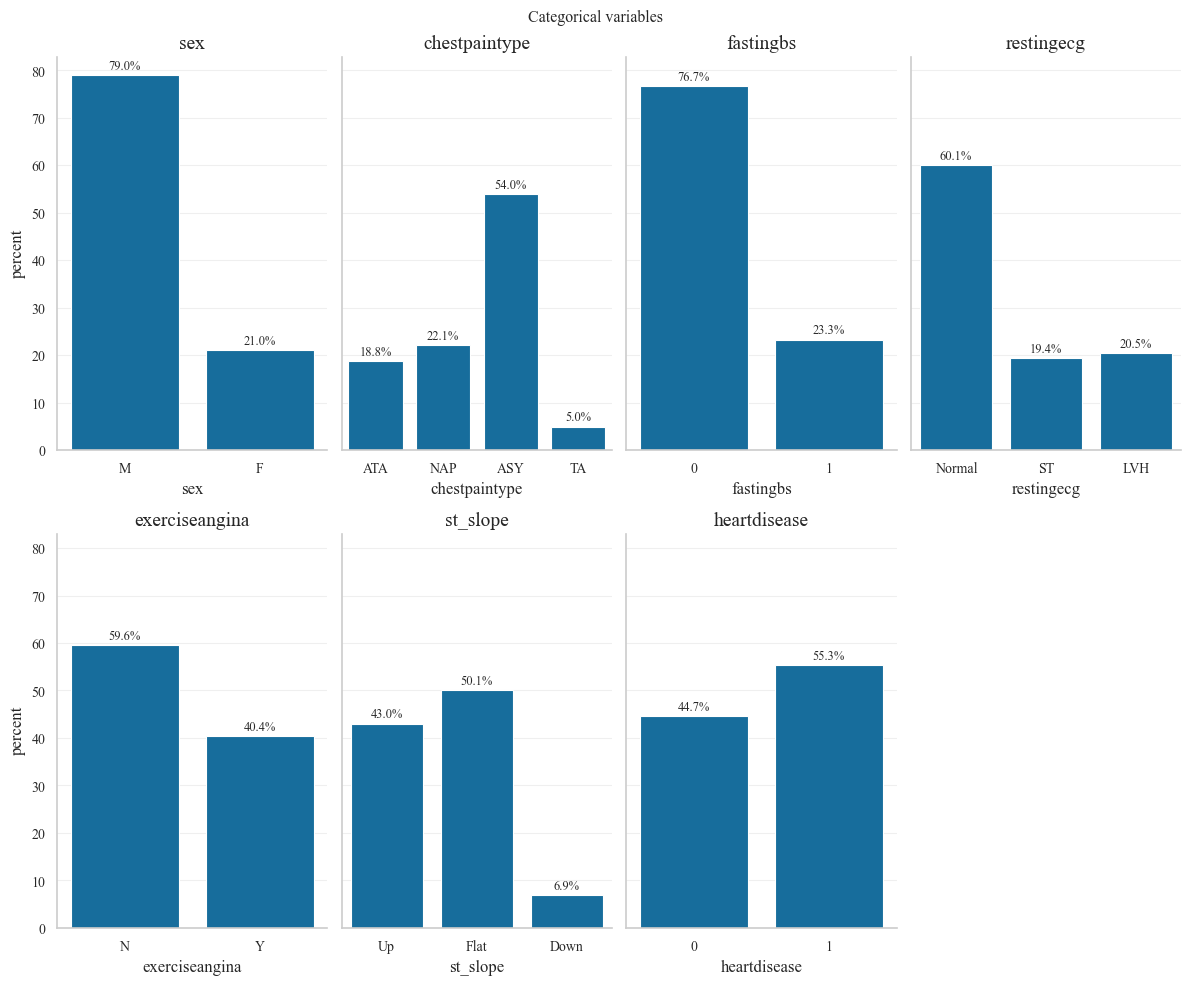

In [8]:
fig, axes = plt.subplots(2, 4, figsize=(12, 10), sharey=True)
axes = axes.flatten()
fig.suptitle('Categorical variables')

for ax, col in zip(axes, CAT_COLS):
    sns.countplot(data=data, x=col, stat='percent', ax=ax)
    ax.set_title(col)

    for bar in ax.patches:
        ax.annotate(f'{bar.get_height():.1f}%',
                    (bar.get_x() + bar.get_width() / 2, bar.get_height()),
                    ha='center', va='bottom', fontsize=9,
                    xytext=(0, 2), textcoords='offset points')

axes[-1].set_visible(False)
plt.tight_layout()
plt.show()

In [9]:
# How each category splits between men and women.
for col in CAT_COLS:
    share = data.groupby('sex')[col].value_counts() / len(data) * 100
    print(share.round(2), '\n')

sex
F    21.02
M    78.98
Name: count, dtype: float64 

sex  chestpaintype
F    ASY               7.63
     ATA               6.54
     NAP               5.77
     TA                1.09
M    ASY              46.41
     NAP              16.34
     ATA              12.31
     TA                3.92
Name: count, dtype: float64 

sex  fastingbs
F    0            18.19
     1             2.83
M    0            58.50
     1            20.48
Name: count, dtype: float64 

sex  restingecg
F    Normal        12.85
     LVH            5.12
     ST             3.05
M    Normal        47.28
     ST            16.34
     LVH           15.36
Name: count, dtype: float64 

sex  exerciseangina
F    N                 16.34
     Y                  4.68
M    N                 43.25
     Y                 35.73
Name: count, dtype: float64 

sex  st_slope
F    Up          12.09
     Flat         8.17
     Down         0.76
M    Flat        41.94
     Up          30.94
     Down         6.10
Name: count, dty

Population of female in this dataset is less, female with heart disease is even less

Categories that have hight percentage of heart disease:

- Exerciseangina = Y
- Flat st_slope
- ASY chestpaintype
- Male
- Normal RestingECG